In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl
import seaborn as sns
import gseapy as gp
from tqdm.auto import tqdm
from pathlib import Path
import yaml

In [48]:
config = yaml.safe_load(open("../configuration/config.yaml"))
perturbation_colors = config['perturbation_colors']
cell_lines = config['cell_lines']
cell_line_colors = config['cell_line_colors']
perturbations = config['perturbations']
actual_perturbations = config['actual_perturbations']
DIR = Path(config['DIR'])

# Count Data Analysis

In [51]:
df_vst = pd.read_csv("../results/count_matrix_vst.csv", header=0, index_col=0)
coldata = pd.read_csv("../results/coldata.tsv", sep='\t', header=0, index_col=0)

FileNotFoundError: [Errno 2] No such file or directory: '../results/count_matrix_vst.csv'

In [39]:
coldata.perturbation.unique()

array(['FBL', 'FTL', 'MALAT1', 'MOCK', 'NEAT1', 'NT', 'RUBY', 'SNHG15',
       'SNHG16', 'VIM', 'LINC', 'PPIA'], dtype=object)

In [40]:
coldata.head()

,line,genotype,perturbation,guide,replicate
75CAS_FBL_V1_R1,H1975,CAS,FBL,1.0,R1
75CAS_FBL_V1_R2,H1975,CAS,FBL,1.0,R2
75CAS_FBL_V1_R3,H1975,CAS,FBL,1.0,R3
75CAS_FBL_V2_R1,H1975,CAS,FBL,2.0,R1
75CAS_FBL_V2_R2,H1975,CAS,FBL,2.0,R2


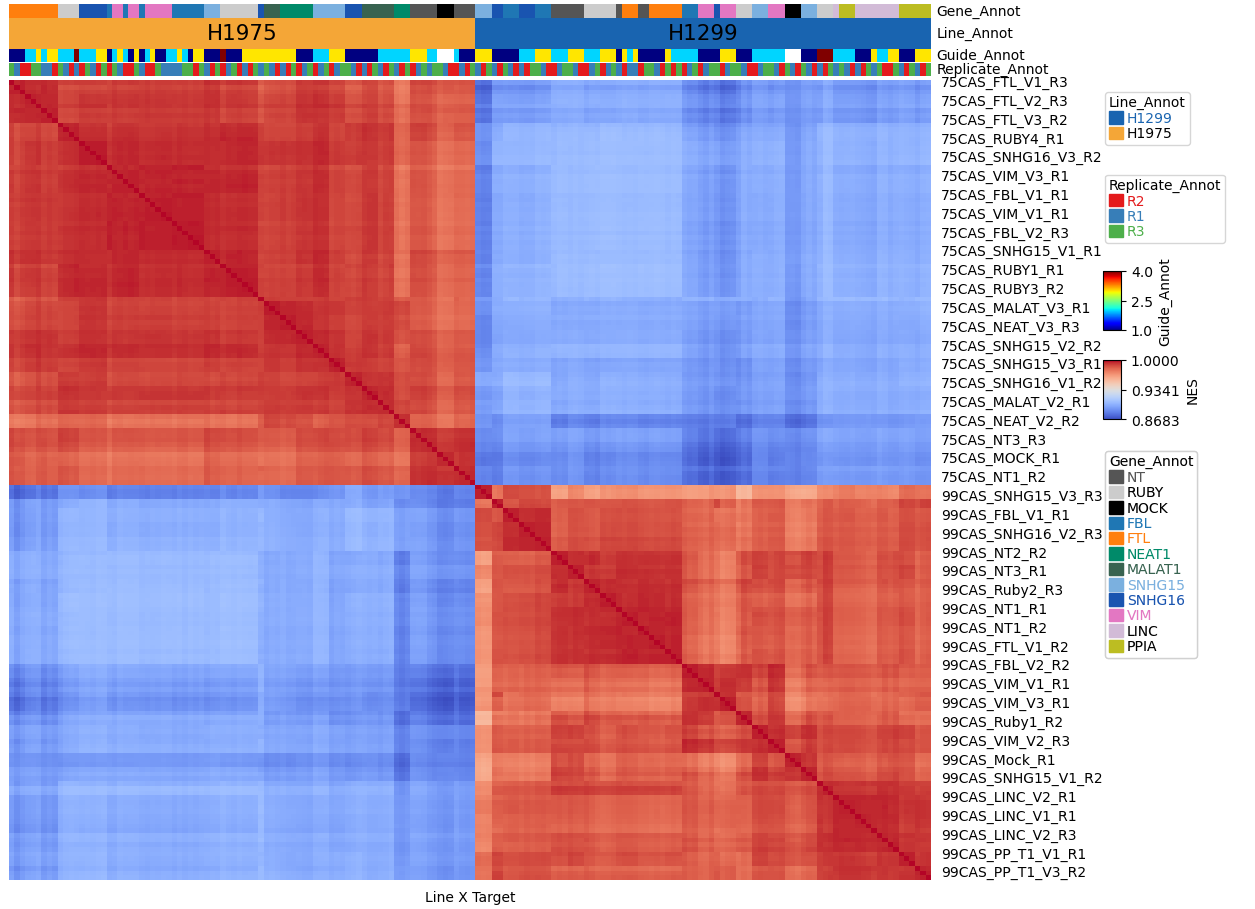

In [41]:
import PyComplexHeatmap as pch
corr = df_vst.corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(coldata.perturbation, add_text=False, colors=perturbation_colors),
    Line_Annot=pch.anno_simple(coldata.line, add_text=True, colors=cell_line_colors, height=7),
    Guide_Annot=pch.anno_simple(coldata.guide, add_text=False),
    Replicate_Annot=pch.anno_simple(coldata.replicate, add_text=False),
    axis=1, verbose=0,
)

# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=True,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    # left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Line X Target", label='NES',
)

In [34]:
scolData.perturbation.unique()

array(['FBL', 'FTL', 'LINC', 'MOCK', 'NT', 'PPIA_T1', 'RUBY', 'SNHG15',
       'SNHG16', 'VIM'], dtype=object)

Incresing ncol
Incresing ncol
More than 3 cols is not supported
Legend too long, generating a new column..


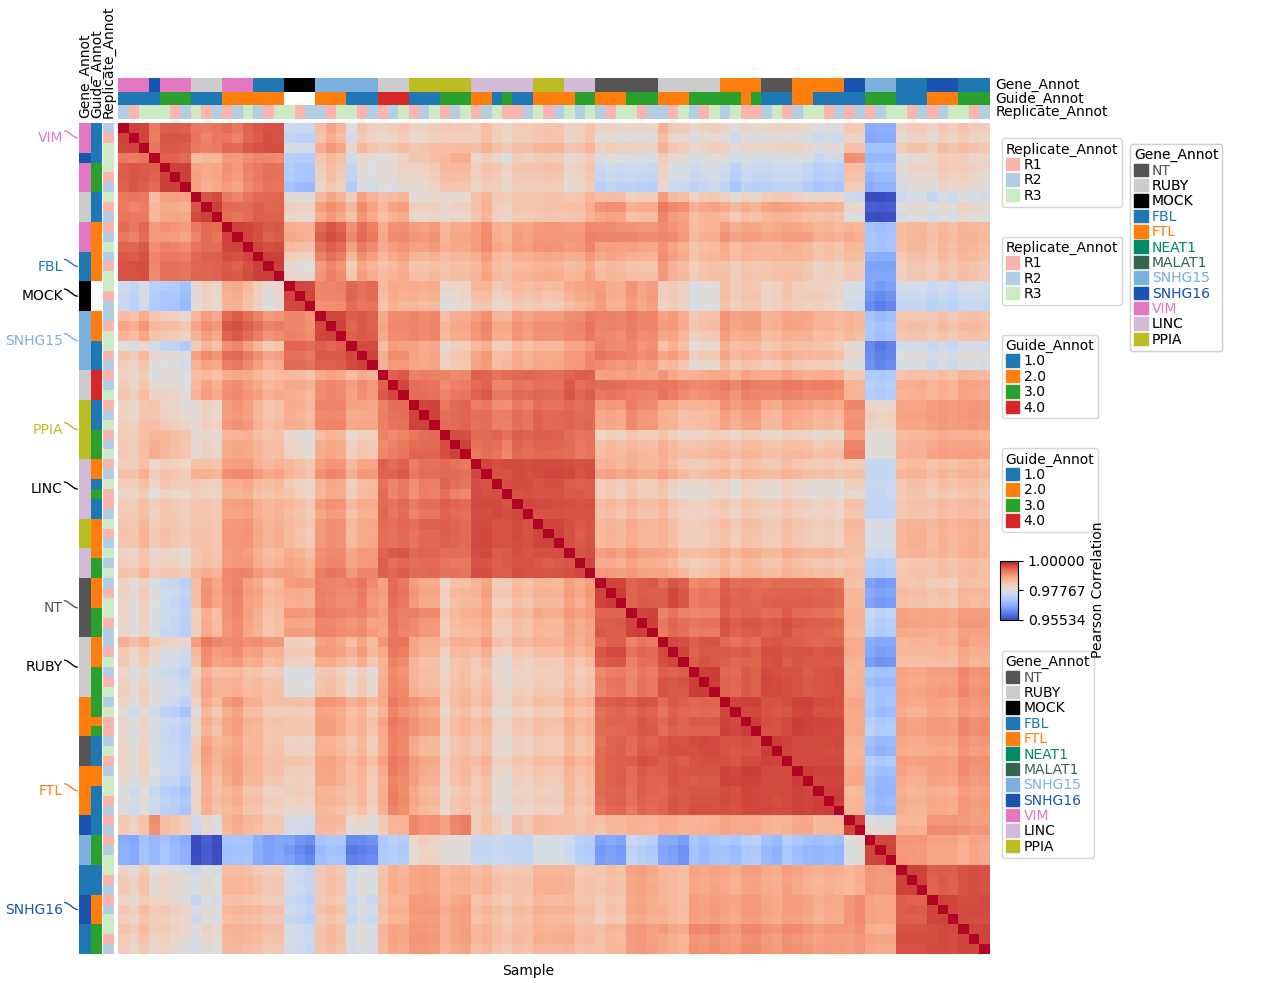

In [42]:
import PyComplexHeatmap as pch

scolData = coldata[coldata.line == 'H1299']
corr = df_vst[scolData.index].corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=1, verbose=0,
)
row_annotations = pch.HeatmapAnnotation(
    Gene_Label=pch.anno_label(scolData.perturbation, merge=True, colors=perturbation_colors),
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=0, verbose=0,
)
# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=False,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Sample", label='Pearson Correlation',
)

In [43]:
import PyComplexHeatmap as pch

scolData = coldata[coldata.line == 'H1975']
corr = df_vst[scolData.index].corr()

col_annotations = pch.HeatmapAnnotation(
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=1, verbose=0,
)
row_annotations = pch.HeatmapAnnotation(
    Gene_Label=pch.anno_label(scolData.perturbation, merge=True, colors=perturbation_colors),
    Gene_Annot=pch.anno_simple(scolData.perturbation, add_text=False, colors=perturbation_colors),
    Guide_Annot=pch.anno_simple(scolData.guide, add_text=False, cmap='tab10'),
    Replicate_Annot=pch.anno_simple(scolData.replicate, add_text=False, cmap='Pastel1'),
    axis=0, verbose=0,
)
# Plot the heatmap
fig, ax = pl.subplots(figsize=(12, 10))
heatmap = pch.ClusterMapPlotter(
    data=corr,
    row_cluster=True, col_cluster=True,  # Disable clustering
    show_colnames=False, show_rownames=False,
    cmap='coolwarm',
    robust=True,
    # linecolor="white",
    vmax=1,
    # linewidths=1,
    left_annotation=row_annotations,  # Add row annotations
    top_annotation=col_annotations,  # Add column annotations
    verbose=0,
    xlabel="Sample", label='Pearson Correlation',
)

KeyError: "['75WT_RUBY4_R2', '75WT_RUBY4_R3'] not in index"

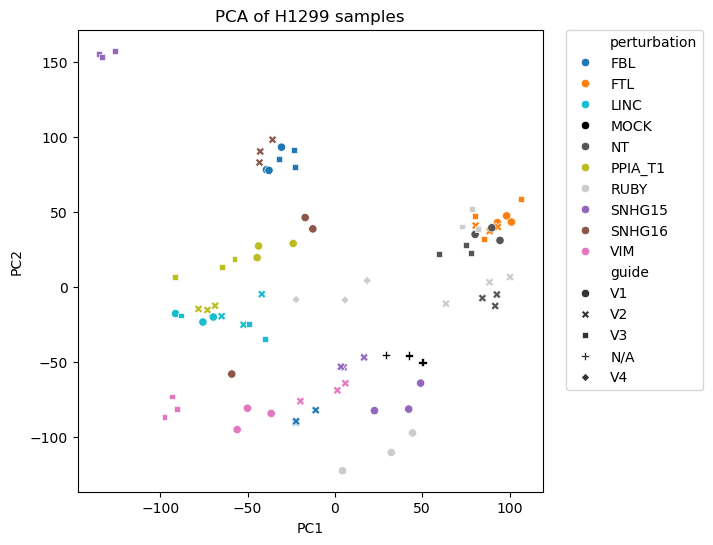

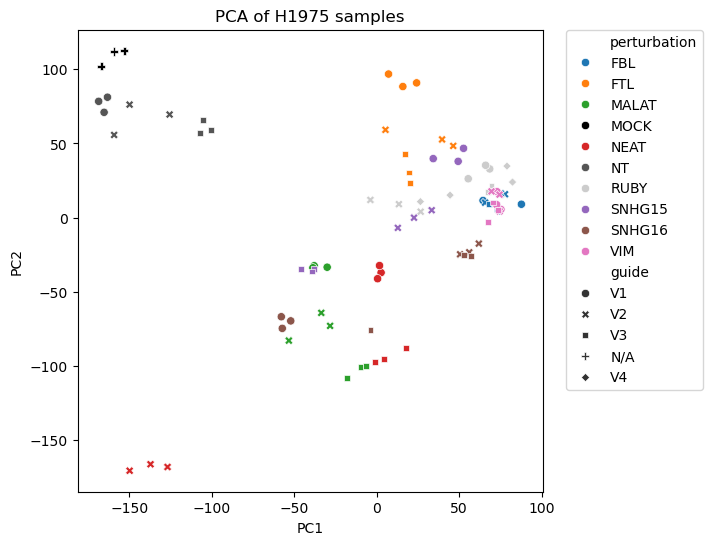

In [180]:
# PCA plot
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

for line in ['H1299', 'H1975']:
    scolData = coldata[coldata.line == line]
    embedding = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(df_vst[scolData.index].T))
    pca_df = pd.DataFrame(embedding, columns=['PC1', 'PC2'], index=scolData.index).join(scolData)
    pca_df.loc[pca_df.perturbation=='MOCK', 'guide'] = 'N/A'  # Otherwise there is no plots made for MOCK
    fig, ax = pl.subplots(figsize=(6, 6))
    sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='perturbation', style='guide', palette=perturbation_colors, ax=ax)
    ax.set_title(f'PCA of {line} samples')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    pl.show()

# Vis Deseq2 results

In [86]:
# Aggregate DESeq2 results
res = {}
for cell_line in cell_lines:
    for file in Path(f"../results/deseq2/{cell_line}").glob("*_deseq2_results.csv"):
        gene = file.stem.split("_")[0]
        gene = 'LINC-PINT' if gene == 'LINC' else gene
        df = pd.read_csv(file, index_col=0)
        res[(cell_line, gene)] = df
tab = pd.concat(res, axis=1)

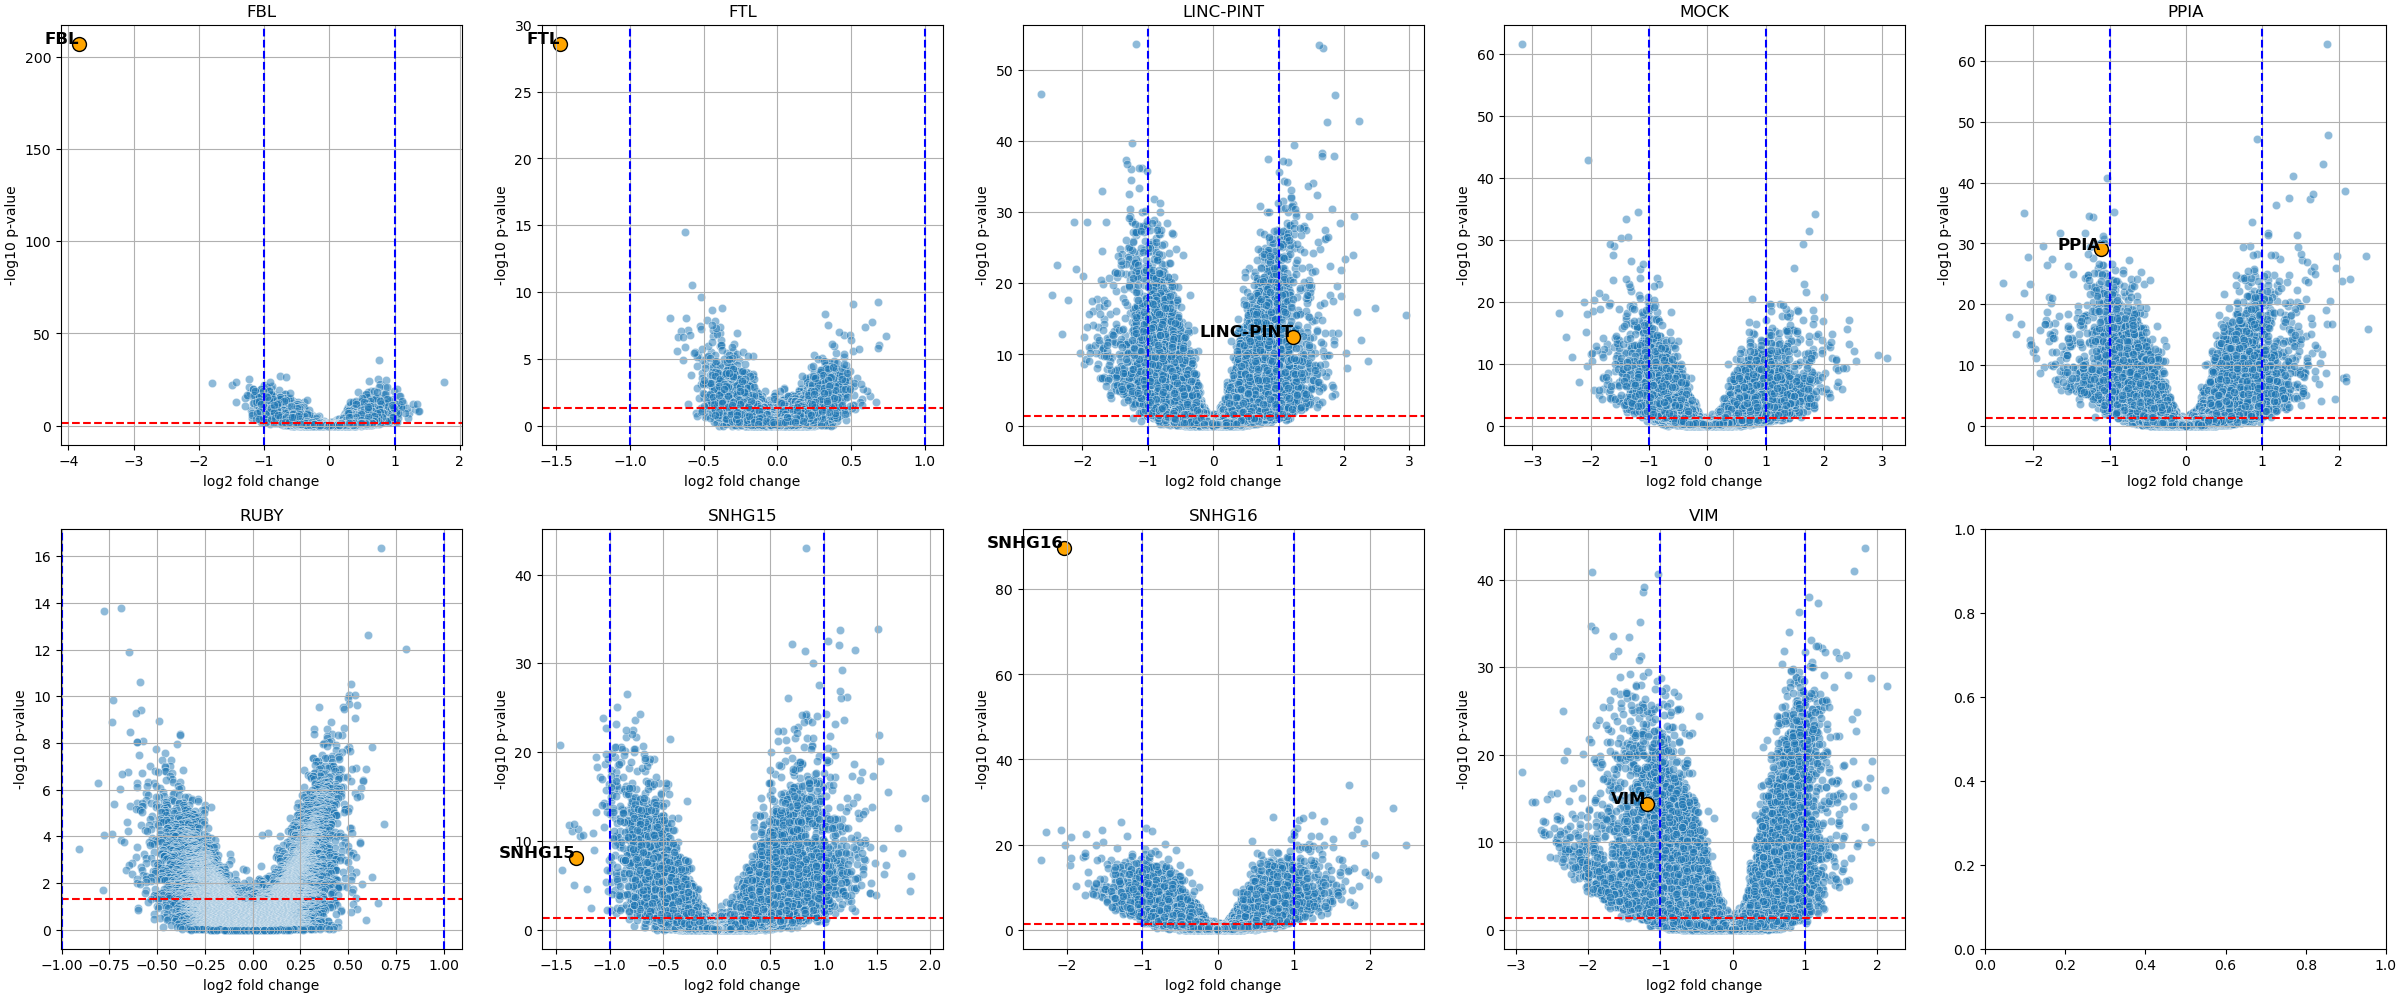

/home/peidli/miniconda3/envs/py_env/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_813925/3047965393.py:21: RuntimeWarning: divide by zero encountered in log10
  ax.scatter(target_df['log2FoldChange'], -np.log10(target_df['pvalue']), color='orange', s=100, edgecolor='black')
/tmp/ipykernel_813925/3047965393.py:22: RuntimeWarning: divide by zero encountered in log10
  ax.text(target_df['log2FoldChange'], -np.log10(target_df['pvalue']), gene, fontsize=12, weight='bold', ha='right')
posx and posy should be finite values
posx and posy should be finite values


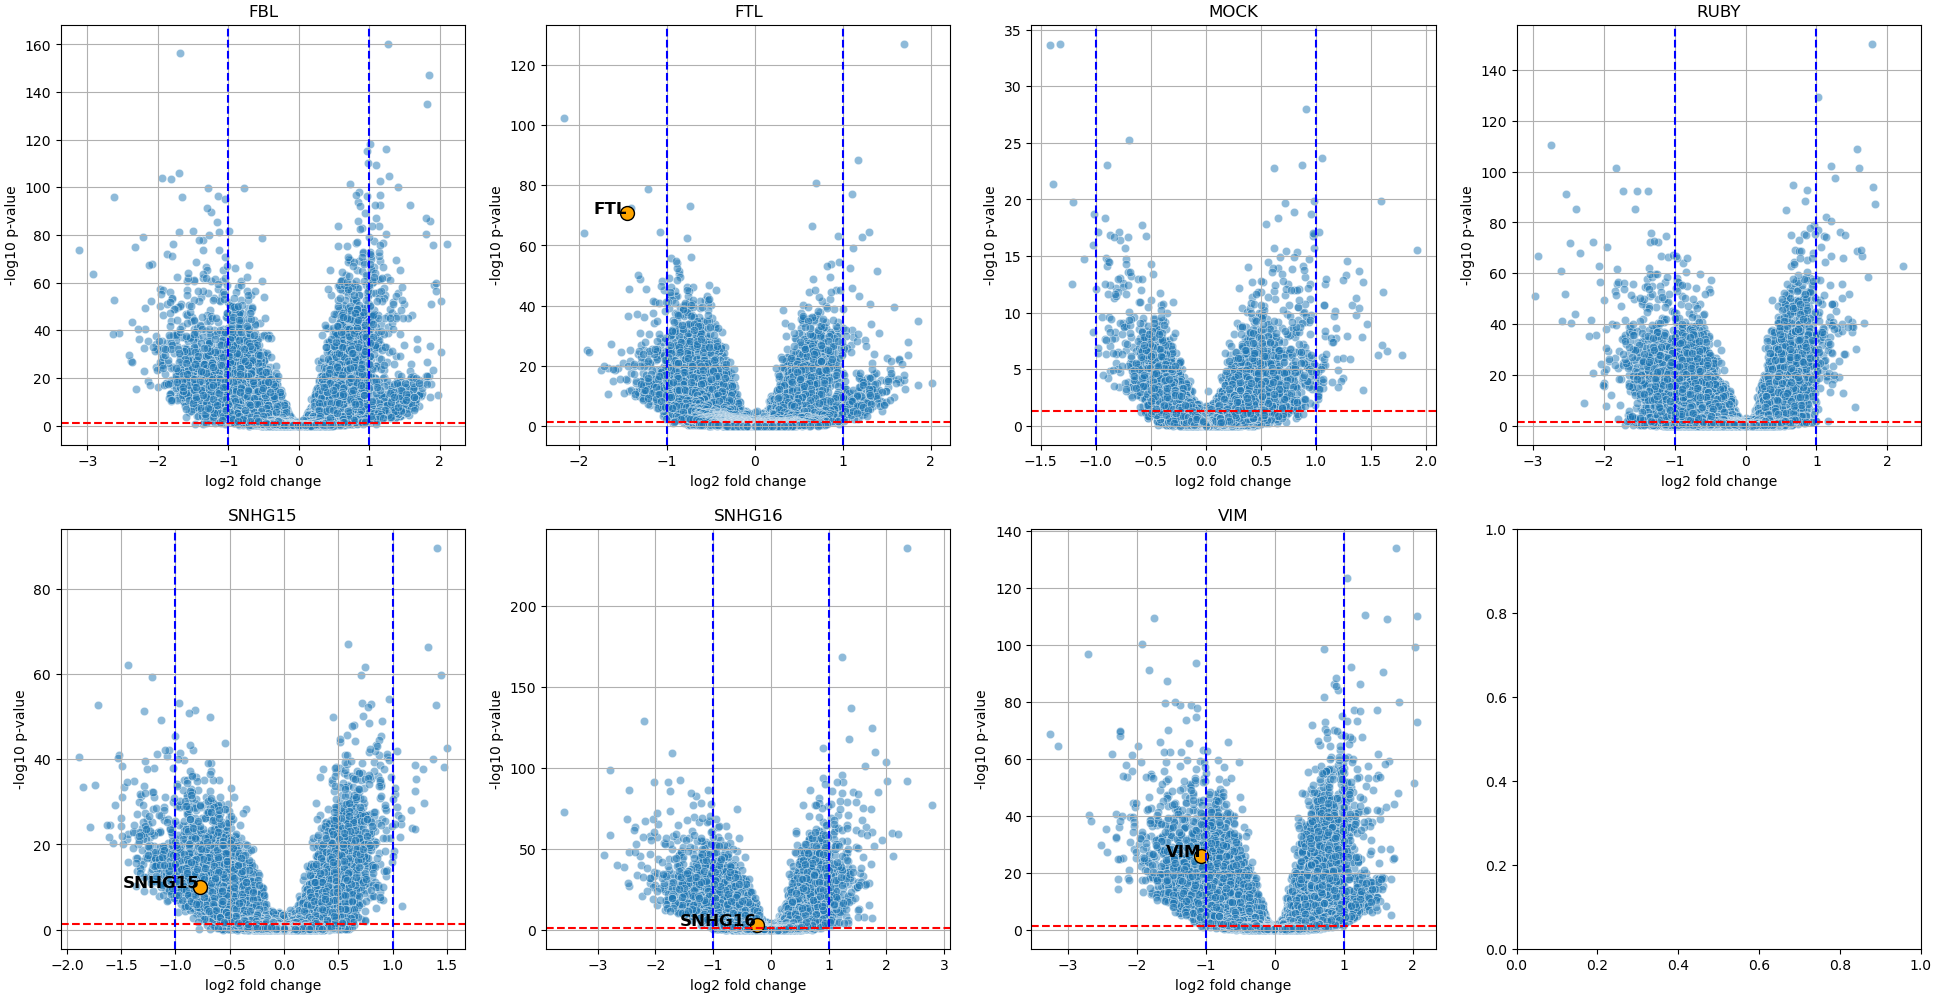

In [89]:
# Vulcano plot per target gene
for cell_line in cell_lines:
    stab = tab[cell_line]
    genes = sorted(list(stab.columns.get_level_values(0).unique()))
    nrows = 2
    ncols = int(np.ceil(len(genes)/nrows))
    fig, axs = pl.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
    for ax, gene in zip(axs.flat, genes):
        df = stab[gene]
        sns.scatterplot(data=df, x='log2FoldChange', y=-np.log10(df['pvalue']), alpha=0.5, ax=ax)
        ax.set_title(gene)
        ax.set_xlabel('log2 fold change')
        ax.set_ylabel('-log10 p-value')
        ax.axhline(-np.log10(0.05), color='red', linestyle='--')
        ax.axvline(1, color='blue', linestyle='--')
        ax.axvline(-1, color='blue', linestyle='--')
        ax.grid(True)
        # Mark target gene
        if gene in df.index:
            target_df = df.loc[gene]
            ax.scatter(target_df['log2FoldChange'], -np.log10(target_df['pvalue']), color='orange', s=100, edgecolor='black')
            ax.text(target_df['log2FoldChange'], -np.log10(target_df['pvalue']), gene, fontsize=12, weight='bold', ha='right')
    pl.show()

# GSEA

In [ ]:
# For each perturbation and cell line, use the DEGs from Wilcoxon rank-sum test
# We accept that the resulting gene lists are heavily enriched with FDR genes,
# since we just want to run GSEA on top of it.
results = {}
genes = list(tab.index.get_level_values(1).unique())
# for cell_line in tqdm(cell_lines):
for gene in genes:
    df = sig_degs[(sig_degs['cell_line'] == cell_line) & (sig_degs['target'] == target)]
    df.sort_values('scores', inplace=True)
    pre_res = gp.prerank(rnk=df[['gene', 'scores']],
                    gene_sets='MSigDB_Hallmark_2020,KEGG_2021_Human',
                    threads=4,
                    min_size=5,
                    max_size=1000,
                    permutation_num=100,
                    outdir=None, # don't write to disk
                    seed=42,
                    verbose=False,
                    no_plot=True,
                )
    results[(cell_line, target)] = pre_res.res2d

,index,score
0,Z98257.1,-71.539084
1,RBBP8NL,-57.979242
2,ANKRD33,-51.741569
3,KRT16P2,-47.780443
4,ALDH3B2,-41.164263
...,...,...
15808,COQ10B,38.964231
15809,ZMPSTE24,41.408323
15810,PPP2CA,41.408323
15811,CLCN4,53.034623


In [93]:
gsea_results = {}
for gene in tqdm(genes):
    df = tab.loc[:, gene]
    df = df[(df.baseMean > 10) & (~df.padj.isna())]
    df['score'] = -np.log10(df.padj) * np.sign(df.log2FoldChange)
    df.sort_values('score', inplace=True)

    pre_res = gp.prerank(rnk=df.reset_index()[['index', 'score']],
                        gene_sets='MSigDB_Hallmark_2020',#,KEGG_2021_Human',
                        threads=4,
                        min_size=5,
                        max_size=1000,
                        permutation_num=100,
                        outdir=None, # don't write to disk
                        seed=42,
                        verbose=False,
                        no_plot=True,
                    )
    gsea_results[gene] = pre_res.res2d

  0%|          | 0/11 [00:00<?, ?it/s]

2025-09-04 12:35:09,230 [WARNING] Duplicated values found in preranked stats: 7.14% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:09,644 [WARNING] Duplicated values found in preranked stats: 12.08% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:10,055 [WARNING] Duplicated values found in preranked stats: 8.06% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:10,500 [WARNING] Duplicated values found in preranked stats: 9.65% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:10,910 [WARNING] Duplicated values found in preranked stats: 24.87% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-09-04 12:35:11,344 [WARNING] Duplicated values found in preranked stats: 7.15% of genes
The order of those genes will 

/tmp/ipykernel_3307781/1057318274.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_df.sort_values('NES', ascending=False, inplace=True)
/tmp/ipykernel_3307781/1057318274.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_df.sort_values('NES', ascending=False, inplace=True)
/tmp/ipykernel_3307781/1057318274.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res_df.sort_values('NES', ascending=False, inplace=True)
/tmp/ipyke

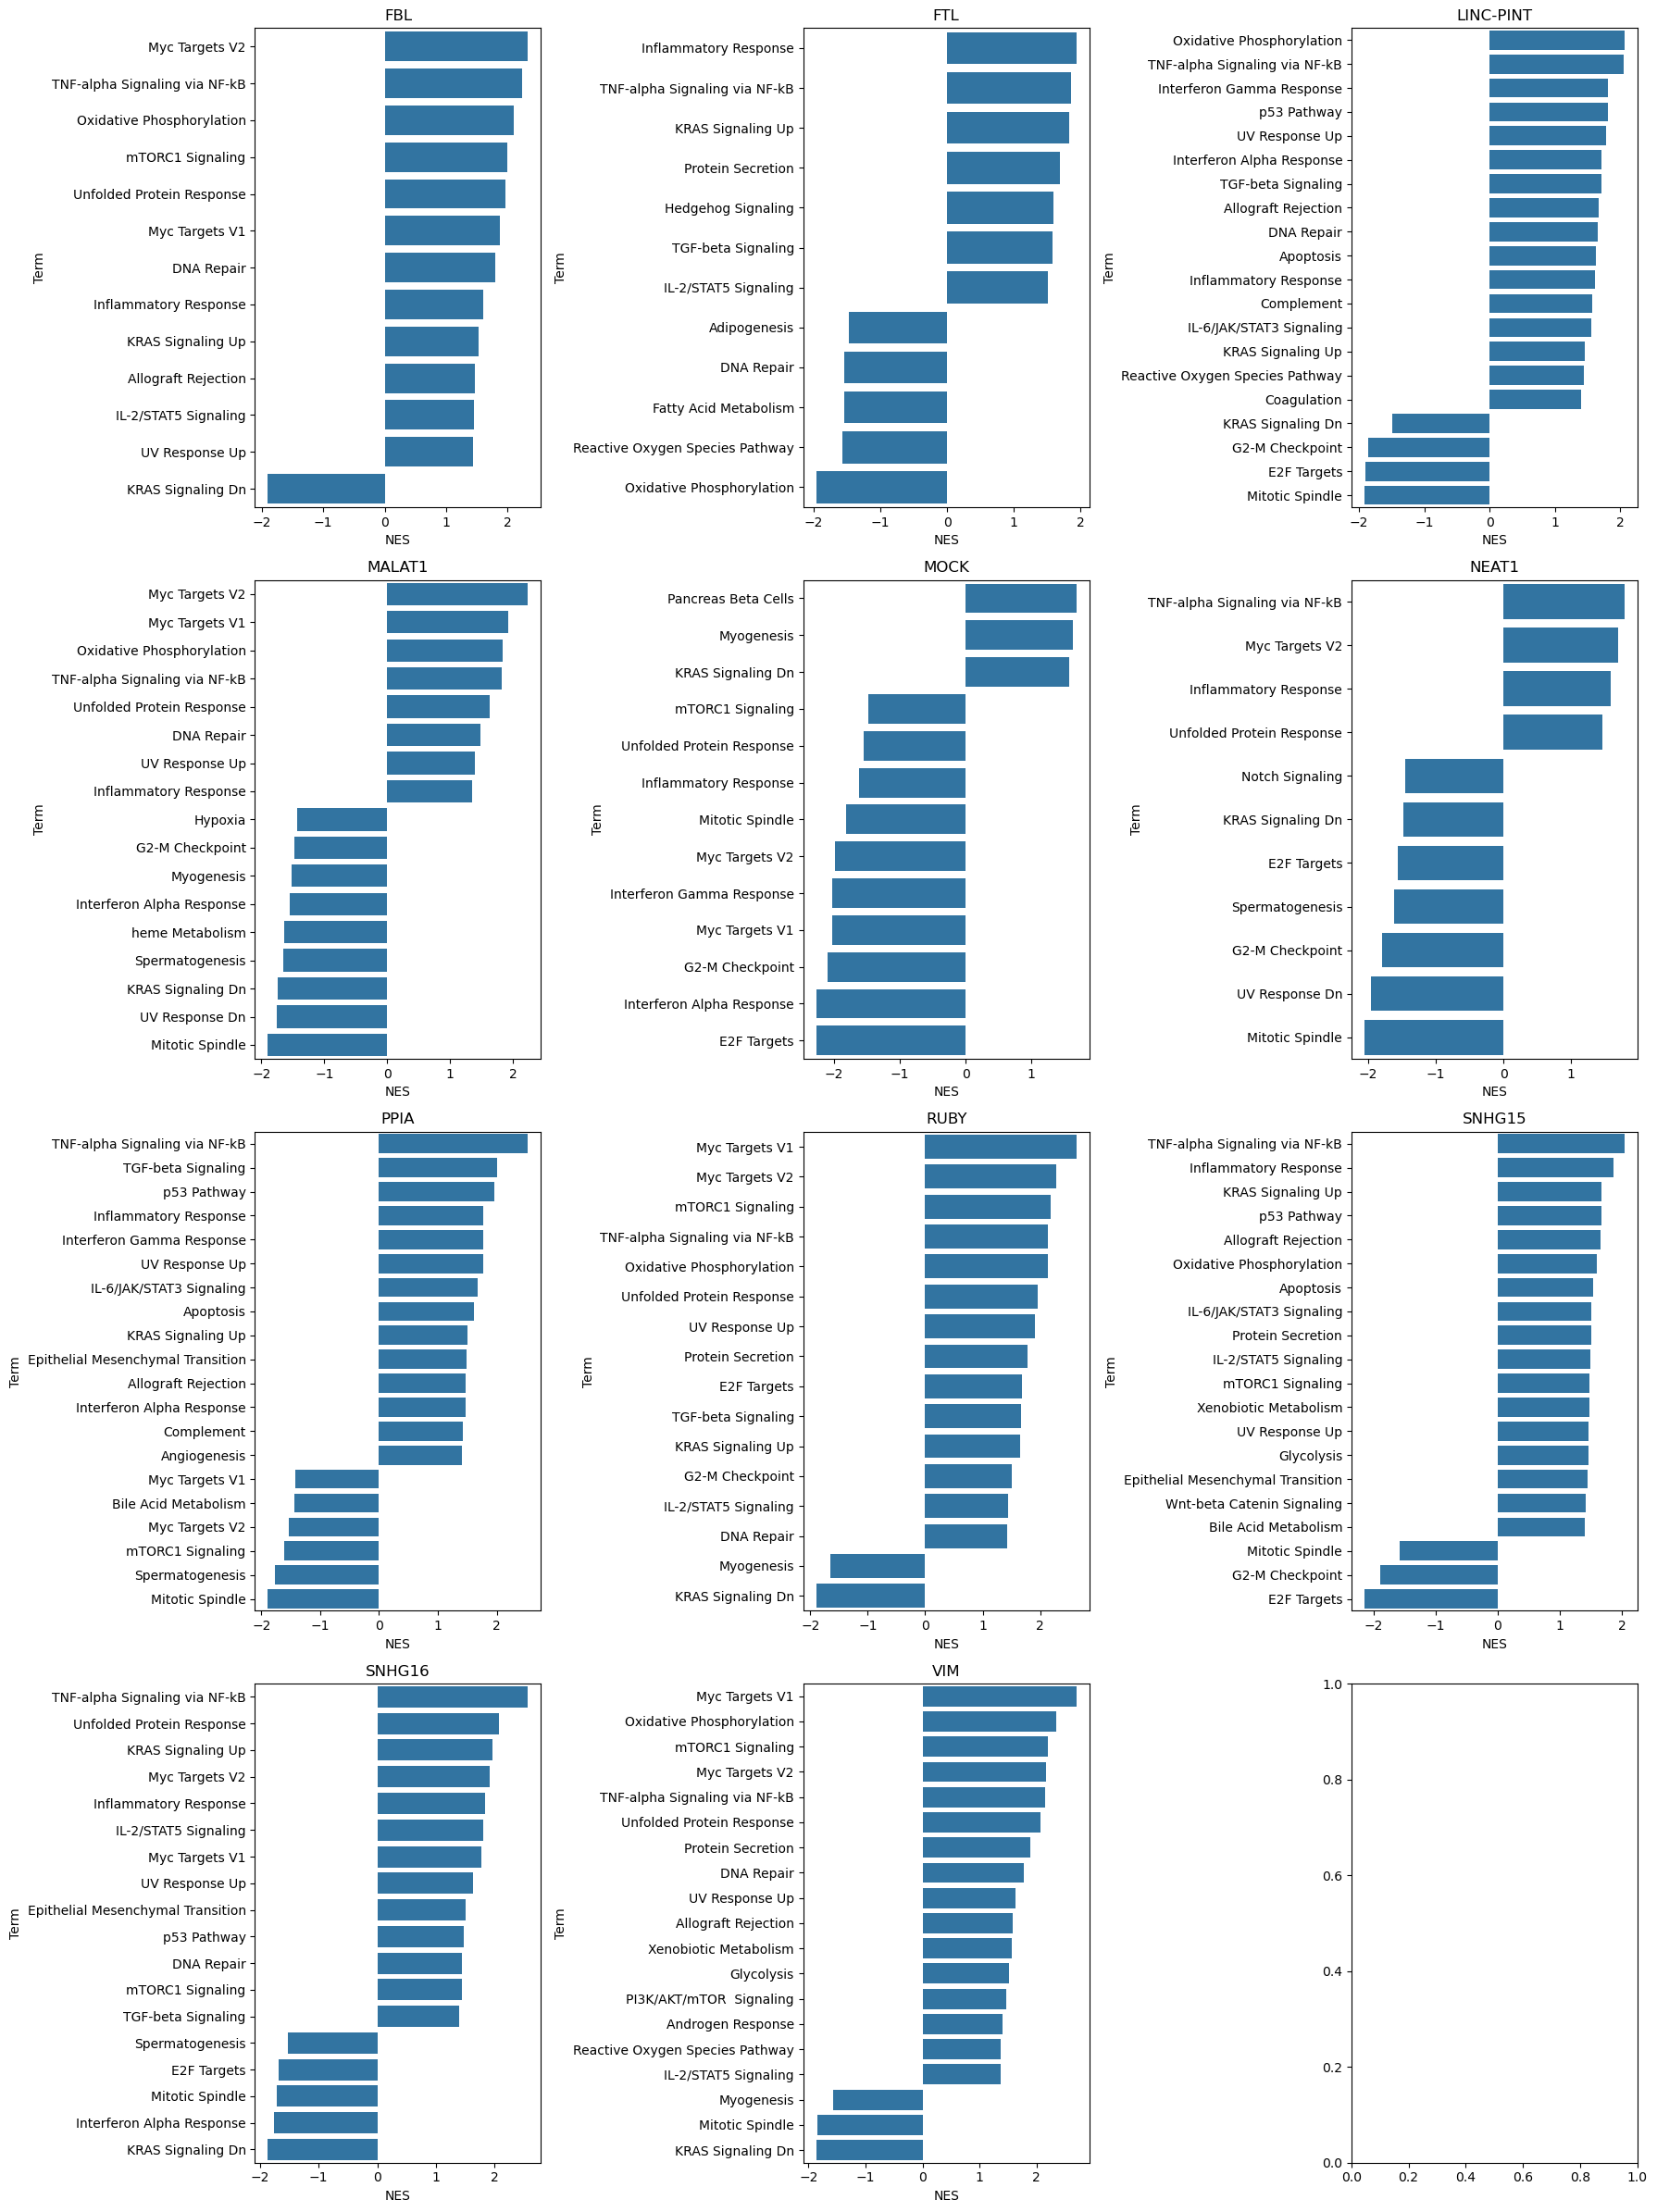

In [98]:
nrows = 4
ncols = int(np.ceil(len(genes)/nrows))
fig, axs = pl.subplots(nrows, ncols, figsize=(6*ncols, 6*nrows))
for gene, ax in zip(genes, axs.flat):
    res_df = gsea_results[gene]
    res_df = res_df[res_df['FDR q-val'] < 0.05]
    res_df.sort_values('NES', ascending=False, inplace=True)
    sns.barplot(data=res_df.head(20), y='Term', x='NES', ax=ax)
    ax.set_title(gene)
pl.tight_layout()
pl.show()

In [107]:
mat = pd.concat(gsea_results, axis=0).reset_index(level=0, names='gene').pivot(index='Term', columns='gene', values='NES')
mat = mat.astype(float)

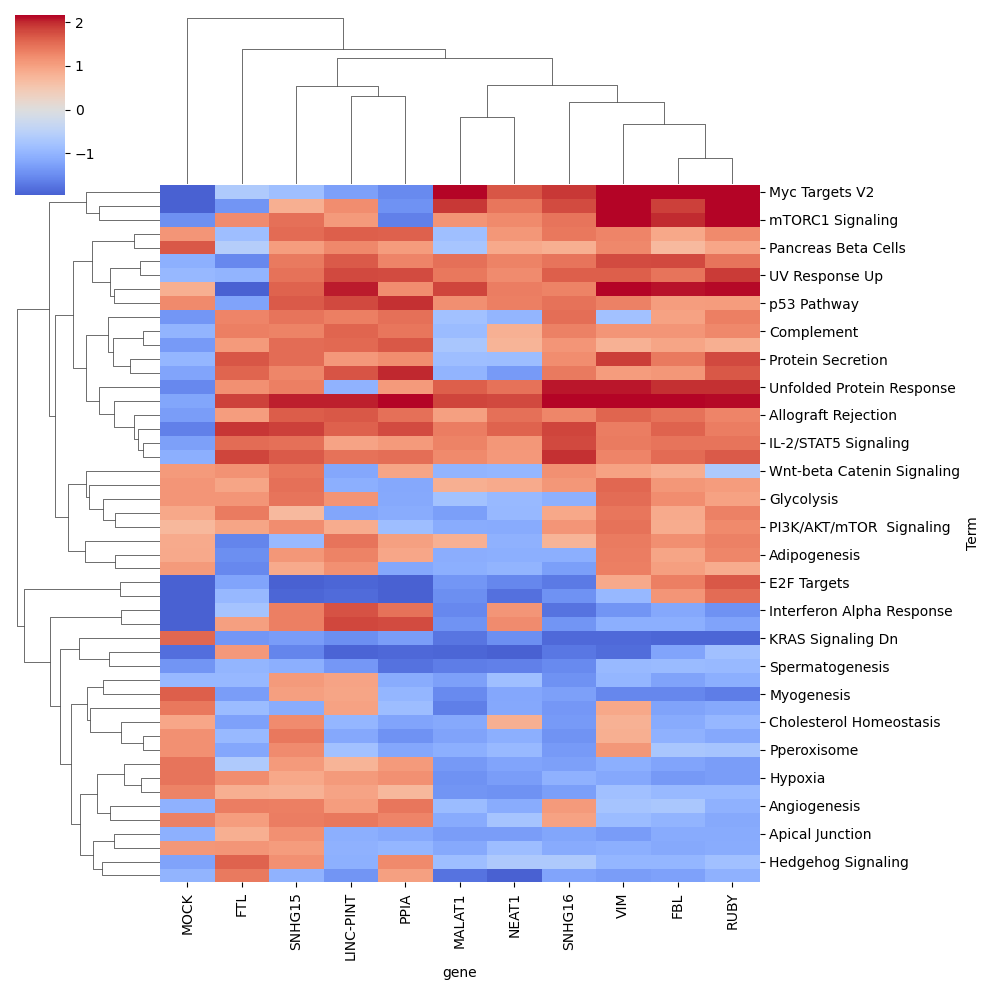

In [113]:
sns.clustermap(mat, cmap='coolwarm', center=0, robust=True)